# 03 · Exploració per a P2: què avança o endarrereix l'edat a la fallada

Resposta: `edat_neta`, l'edat del mòbil el dia de la reparació (fins a 15 anys). Gairebé sempre ve en anys sencers, però alguns registres tenen mitjos anys o dècimes. Recordeu que és l'edat **dels mòbils que arriben espatllats**, no la vida útil.

In [1]:
import sys
sys.path.insert(0, "..")

import matplotlib.pyplot as plt
import pandas as pd

import comu

pd.set_option("display.max_rows", 40)

mobils = pd.read_csv(comu.PROCESSADES / "mobils.csv")
mobifix = comu.carrega_mobifix()
amb_edat = mobils.dropna(subset=["edat_neta"])
print(f"Registres amb edat: {len(amb_edat):,} de {len(mobils):,}")
amb_edat["edat_neta"].describe()

Registres amb edat: 1,694 de 5,652


count    1694.000000
mean        4.252066
std         2.803696
min         0.000000
25%         2.000000
50%         4.000000
75%         5.000000
max        15.000000
Name: edat_neta, dtype: float64

## Distribució

L'edat ve gairebé sempre en anys sencers: molts empats, que la regressió quantílica haurà de tractar (apartat 5.2 del disseny).

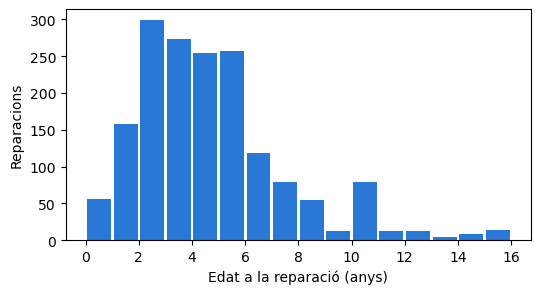

Edat 0: 23  ·  edats que no són anys sencers: 85


In [2]:
ax = amb_edat["edat_neta"].plot.hist(bins=range(0, 17), figsize=(6, 3), color="#2a78d6", rwidth=0.9)
ax.set_xlabel("Edat a la reparació (anys)")
ax.set_ylabel("Reparacions")
plt.show()
no_sencers = (amb_edat["edat_neta"] % 1 != 0).sum()
print(f"Edat 0: {(amb_edat['edat_neta'] == 0).sum()}  ·  edats que no són anys sencers: {no_sencers}")

In [3]:
def quartils(df, columna, minim=30):
    """Mediana i quartils de l'edat per categoria, amb el nombre de casos."""
    g = df.groupby(columna)["edat_neta"]
    t = pd.DataFrame({"n": g.size(), "q25": g.quantile(0.25),
                      "mediana": g.median(), "q75": g.quantile(0.75)})
    return t[t["n"] >= minim].sort_values("mediana")

def caixes(df, columna, titol, minim=30):
    t = quartils(df, columna, minim)
    dades = [df.loc[df[columna] == c, "edat_neta"] for c in t.index]
    fig, ax = plt.subplots(figsize=(6, 0.35 * len(t) + 1))
    ax.boxplot(dades, vert=False, tick_labels=[str(c) for c in t.index])
    ax.set_xlabel("Edat a la reparació (anys)")
    ax.set_title(titol)
    plt.show()
    return t

## Per estat de la reparació

L'estat passa després de la fallada: no és predictor de P2, però ajuda a entendre-la.

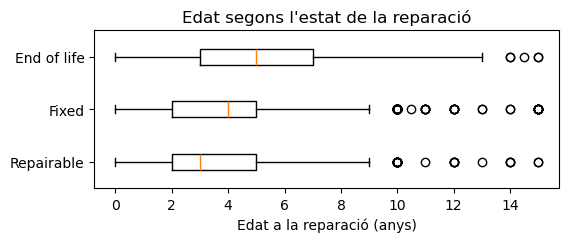

,n,q25,mediana,q75
repair_status,,,,
Repairable,562,2.0,3.0,5.0
Fixed,907,2.0,4.0,5.0
End of life,225,3.0,5.0,7.0


In [4]:
caixes(amb_edat, "repair_status", "Edat segons l'estat de la reparació")

## Per marca, proveïdor i any de l'esdeveniment

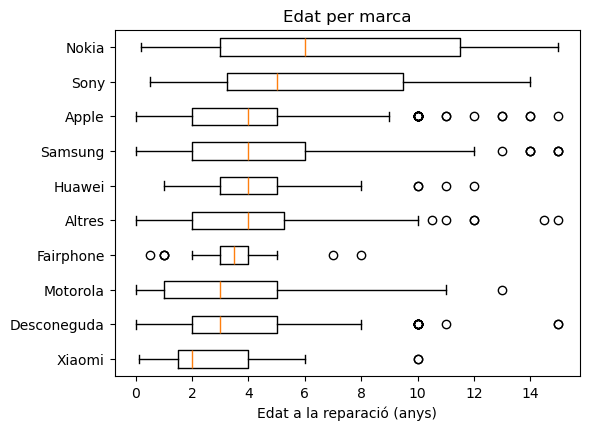

,n,q25,mediana,q75
marca,,,,
Xiaomi,65,1.50,2.0,4.00
Desconeguda,154,2.00,3.0,5.00
Motorola,61,1.00,3.0,5.00
Fairphone,34,3.00,3.5,4.00
Altres,248,2.00,4.0,5.25
Huawei,104,3.00,4.0,5.00
Samsung,457,2.00,4.0,6.00
Apple,482,2.00,4.0,5.00
Sony,42,3.25,5.0,9.50


In [5]:
caixes(amb_edat, "marca", "Edat per marca")

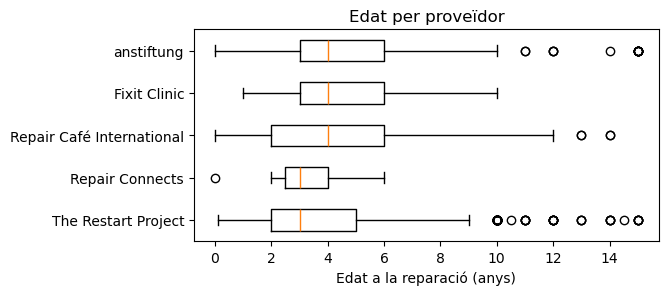

,n,q25,mediana,q75
data_provider,,,,
The Restart Project,1044,2.0,3.0,5.0
Repair Connects,15,2.5,3.0,4.0
Repair Café International,284,2.0,4.0,6.0
Fixit Clinic,13,3.0,4.0,6.0
anstiftung,337,3.0,4.0,6.0


In [6]:
caixes(amb_edat, "data_provider", "Edat per proveïdor", minim=10)

,n,q25,mediana,q75
any_event,,,,
2017,38,1.0,2.00,4.000
2018,160,1.5,2.25,3.625
2019,250,2.0,3.00,5.000
2020,45,2.0,4.00,5.000
2021,58,3.0,4.00,5.000
2022,183,2.0,3.50,6.000
2023,223,2.5,4.00,6.000
2024,278,2.0,4.00,6.000
2025,311,3.0,4.00,6.000


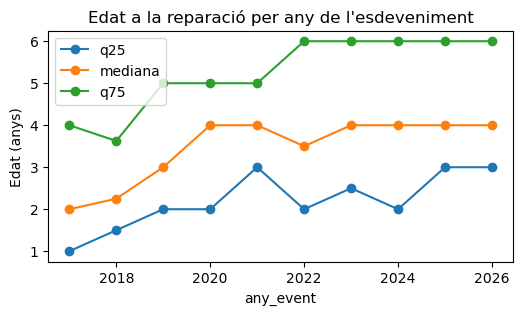

In [7]:
t = quartils(amb_edat, "any_event", minim=1).sort_index()
display(t)
ax = t[["q25", "mediana", "q75"]].plot(marker="o", figsize=(6, 3))
ax.set_ylabel("Edat (anys)")
ax.set_title("Edat a la reparació per any de l'esdeveniment")
plt.show()

## Per tipus d'avaria (MobiFix)

Només 489 registres de MobiFix tenen edat: les categories petites no es poden interpretar.

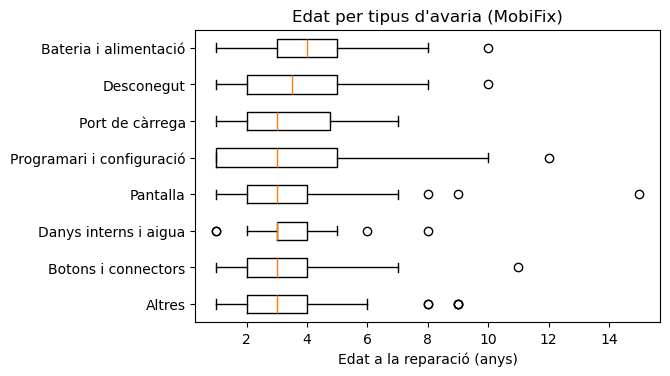

,n,q25,mediana,q75
grup_avaria,,,,
Altres,59,2.0,3.0,4.00
Botons i connectors,31,2.0,3.0,4.00
Danys interns i aigua,13,3.0,3.0,4.00
Pantalla,180,2.0,3.0,4.00
Programari i configuració,55,1.0,3.0,5.00
Port de càrrega,18,2.0,3.0,4.75
Desconegut,52,2.0,3.5,5.00
Bateria i alimentació,65,3.0,4.0,5.00


In [8]:
caixes(mobifix.dropna(subset=["edat_neta"]), "grup_avaria", "Edat per tipus d'avaria (MobiFix)", minim=10)

## Notes per a la fase de models

- Categories amb menys de 30 casos: no s'han d'interpretar soles; caldrà agrupar-les.
- El proveïdor i l'any van junts (cada xarxa registra en anys diferents): cal posar-los tots dos al model.
- Revisar si la pujada de l'edat amb l'any es manté dins de cada proveïdor.

In [9]:
amb_edat.groupby(["data_provider", "any_event"])["edat_neta"].median().unstack(0).round(1)

data_provider,Fixit Clinic,Repair Café International,Repair Connects,The Restart Project,anstiftung,iFixit
any_event,,,,,,
2017,NaN,1.0,NaN,2.5,NaN,NaN
2018,3.0,3.0,NaN,2.0,3.0,NaN
2019,2.5,4.0,NaN,3.0,4.5,NaN
2020,NaN,4.0,NaN,4.0,4.5,NaN
2021,7.0,3.5,3.0,4.0,5.0,NaN
2022,NaN,4.0,3.0,3.0,4.0,NaN
2023,5.0,5.0,NaN,4.0,5.0,NaN
2024,1.0,4.0,NaN,4.0,5.0,NaN
2025,NaN,5.0,NaN,4.0,4.0,NaN
